Code to plot spin split Andreev Bound Spectrum E vs phi

In [9]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
#import Minimal_Model_2D as mm2d
import time

np.set_printoptions(threshold=sys.maxsize)

import Minimal_Model_1D as M



In [34]:
NSM = 65          # in nm
MY = 3             # no of subbands
AX = 1             # lattice spacing in nm
LY = 100           # Width in nm
ALPHAT = 0        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 2000
N = 2*NSC + NSM



print('first subband energy =' , OMEGA/2 , '\n', 'second subband energy =' , 3*OMEGA/2)

MU_SC =  OMEGA   #in between two subbands
MU_SM =  OMEGA   #in between two subbands

print('mu_sc = ',MU_SC)

PHI = np.linspace(-1*np.pi,1*np.pi,101)
K = 12

Ep = np.empty((PHI.shape[0],K))

D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

for i in range(PHI.shape[0]):

    H = D.H_sys(PHI[i], so='li' )
    
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    
    Ep[i,:] =np.sort(E)
    
    if i%10==0:
        print(i)

first subband energy = 0.6631720133634798 
 second subband energy = 1.9895160400904393
mu_sc =  1.3263440267269595
0
10
20
30
40
50
60
70
80
90
100


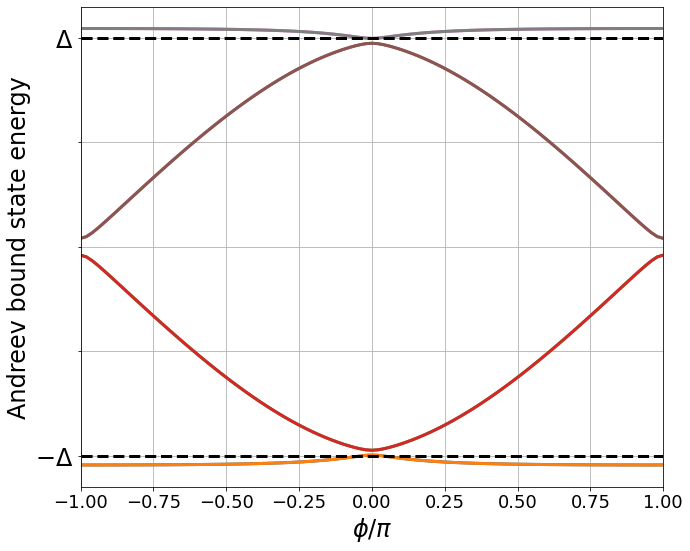

In [47]:

plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

ax = plt.axes()

#Ep2 = Ep[:,2:6]
Ep2 = Ep[:,2:10]

for i in range(Ep2.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.plot(PHI/np.pi, Ep2[:,i]/DELTA, lw=3)

# Increase the font size of the axes labels and title
plt.xlabel(r'$\phi/\pi$', fontsize=24)
plt.ylabel(r'Andreev bound state energy', fontsize=24)
#plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))


# Specify ticks on the y-axis 
ax.set_yticks(np.linspace(-1,1,num=5))

# setting label for y tick 
ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 



# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.show()

In [3]:
NSM = 60          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
LY = 75           # Width in nm
ALPHAT = 20        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 500
N = 2*NSC + NSM



print('first subband energy =' , OMEGA/2 , '\n', 'second subband energy =' , 3*OMEGA/2)

MU_SM = 0.8 + OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.8 + OMEGA/2        ## constant potential over reference level across all widths

print('mu_sc = ',MU_SC , 'mu_sm = ', MU_SM )

PHI = np.linspace(-1*np.pi,1*np.pi,101)
K = 12

Ep_s = np.empty((PHI.shape[0],K))

D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

for i in range(PHI.shape[0]):

    H = D.H_sys(PHI[i], so='li' )
    
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    
    Ep_s[i,:] =np.sort(E)
    
    if i%10==0:
        print(i)


np.save()

first subband energy = 0.8187308806956541 
 second subband energy = 2.4561926420869624
mu_sc =  1.6187308806956542 mu_sm =  1.6187308806956542
0
10
20
30
40
50
60
70
80
90
100


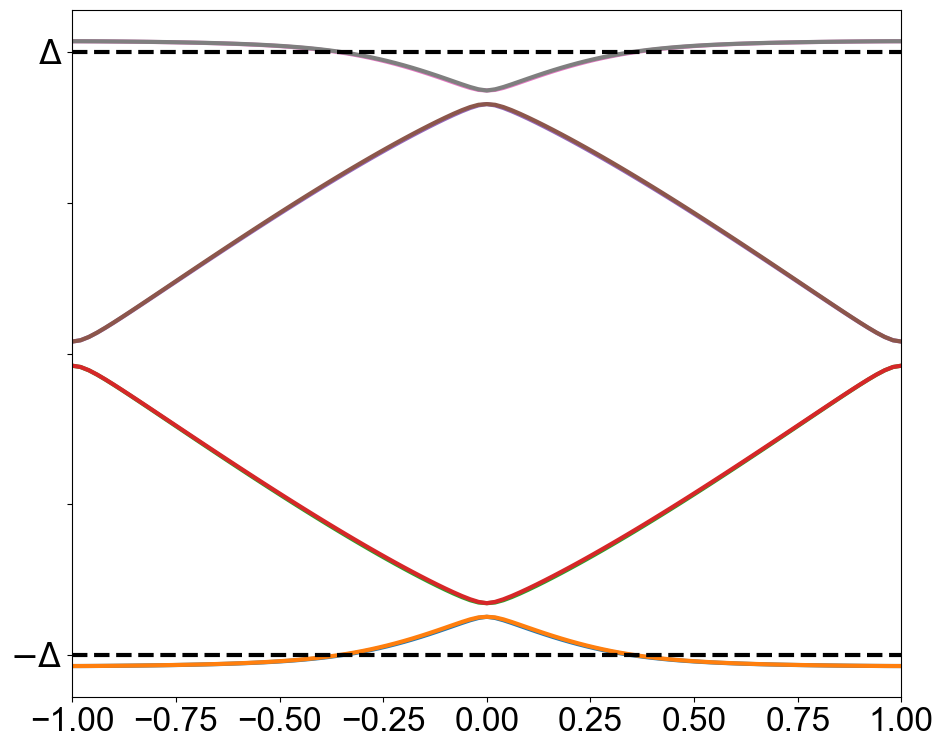

In [5]:

# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

ax = plt.axes()

#Ep2 = Ep[:,2:6]
Ep2_s = Ep_s[:,2:10]

for i in range(Ep2_s.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.plot(PHI/np.pi, Ep2_s[:,i]/DELTA, lw=3)

# Increase the font size of the axes labels and title
#plt.xlabel(r'$\phi/\pi$', fontsize=24)
#plt.ylabel(r'Andreev bound state energy', fontsize=24)
#plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

#plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Specify ticks on the y-axis 
ax.set_yticks(np.linspace(-1,1,num=5))

# setting label for y tick 
ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 


# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.show()

In [11]:
NSM = 60          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
LY = 90           # Width in nm
ALPHAT = 20        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 500
N = 2*NSC + NSM



print('first subband energy =' , OMEGA/2 , '\n', 'second subband energy =' , 3*OMEGA/2)

MU_SM = 0.8 + OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.8 + OMEGA/2        ## constant potential over reference level across all widths

print('mu_sc = ',MU_SC , 'mu_sm = ', MU_SM )

PHI = np.linspace(-0.6*np.pi,-0.4*np.pi,101)
K = 12

Ep_s = np.empty((PHI.shape[0],K))

D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

for i in range(PHI.shape[0]):

    H = D.H_sys(PHI[i], so='li' )
    
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    
    Ep_s[i,:] =np.sort(E)
    
    if i%10==0:
        print(i)

first subband energy = 0.8187308806956541 
 second subband energy = 2.4561926420869624
mu_sc =  1.6187308806956542 mu_sm =  1.6187308806956542
0
10
20
30
40
50
60
70
80
90
100


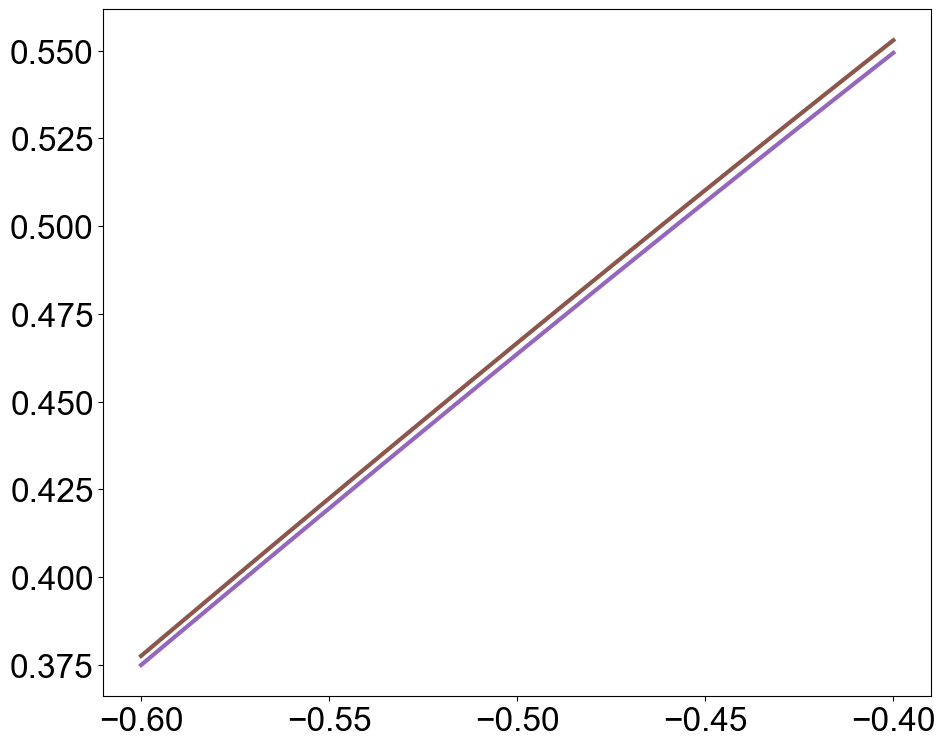

In [16]:

# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

ax = plt.axes()

#Ep2 = Ep[:,2:6]
Ep2_s = Ep_s[:,6:8]

#PHI = np.linspace(-0.6*np.pi,-0.4*np.pi,101)

# Define your custom color sequence
colors = ['#9467bd', '#8c564b']

for i in range(Ep2_s.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.plot(PHI/np.pi, Ep2_s[:,i]/DELTA, lw=3, color= colors[i])

# Increase the font size of the axes labels and title
#plt.xlabel(r'$\phi/\pi$', fontsize=24)
#plt.ylabel(r'Andreev bound state energy', fontsize=24)
#plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

#plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
#plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Specify ticks on the y-axis 
#ax.set_yticks(np.linspace(-1,1,num=5))

# setting label for y tick 
#ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 


# Add dashed lines at +1 and -1 on the y-axis
#plt.axhline(1, color='black', linestyle='dashed', lw=3)
#plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.show()

first subband energy = 0.8187308806956541 
 second subband energy = 2.4561926420869624
mu_sc =  1.6187308806956542 mu_sm =  1.6187308806956542
0
10
20
30
40
50
60
70
80
90
100


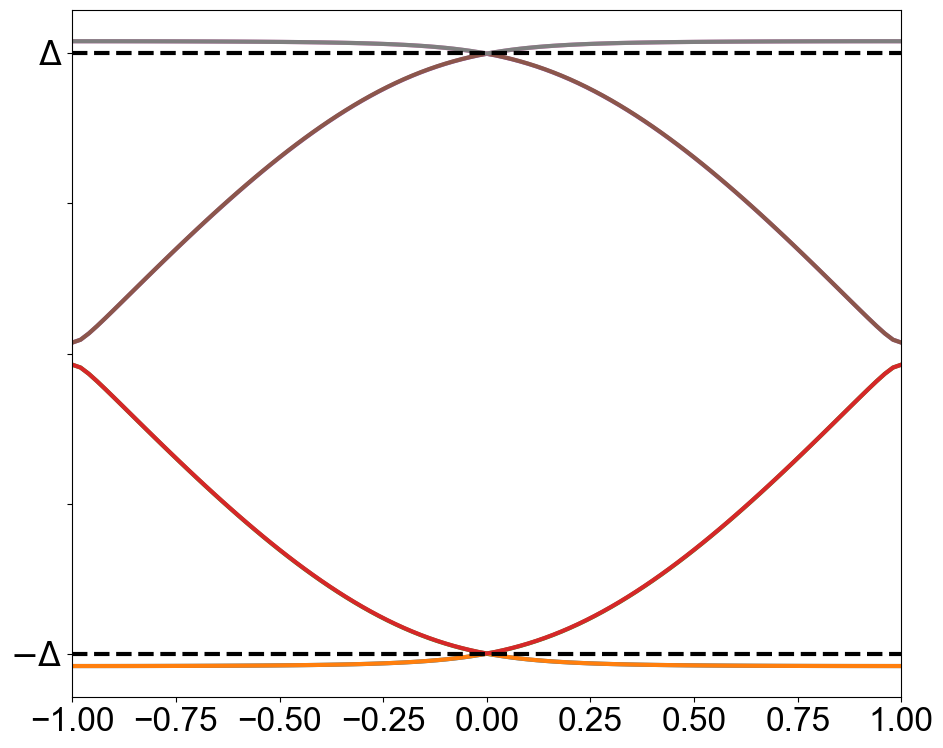

In [6]:
NSM = 10          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
LY = 90           # Width in nm
ALPHAT = 20        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 500
N = 2*NSC + NSM



print('first subband energy =' , OMEGA/2 , '\n', 'second subband energy =' , 3*OMEGA/2)

MU_SM = 0.8 + OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.8 + OMEGA/2        ## constant potential over reference level across all widths

print('mu_sc = ',MU_SC , 'mu_sm = ', MU_SM )

PHI = np.linspace(-1*np.pi,1*np.pi,101)
K = 12

Ep_s = np.empty((PHI.shape[0],K))

D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

for i in range(PHI.shape[0]):

    H = D.H_sys(PHI[i], so='li' )
    
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    
    Ep_s[i,:] =np.sort(E)
    
    if i%10==0:
        print(i)


# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

ax = plt.axes()

#Ep2 = Ep[:,2:6]
Ep2_s = Ep_s[:,2:10]

for i in range(Ep2_s.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.plot(PHI/np.pi, Ep2_s[:,i]/DELTA, lw=3)

# Increase the font size of the axes labels and title
#plt.xlabel(r'$\phi/\pi$', fontsize=24)
#plt.ylabel(r'Andreev bound state energy', fontsize=24)
#plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

#plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Specify ticks on the y-axis 
ax.set_yticks(np.linspace(-1,1,num=5))

# setting label for y tick 
ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 


# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.show()

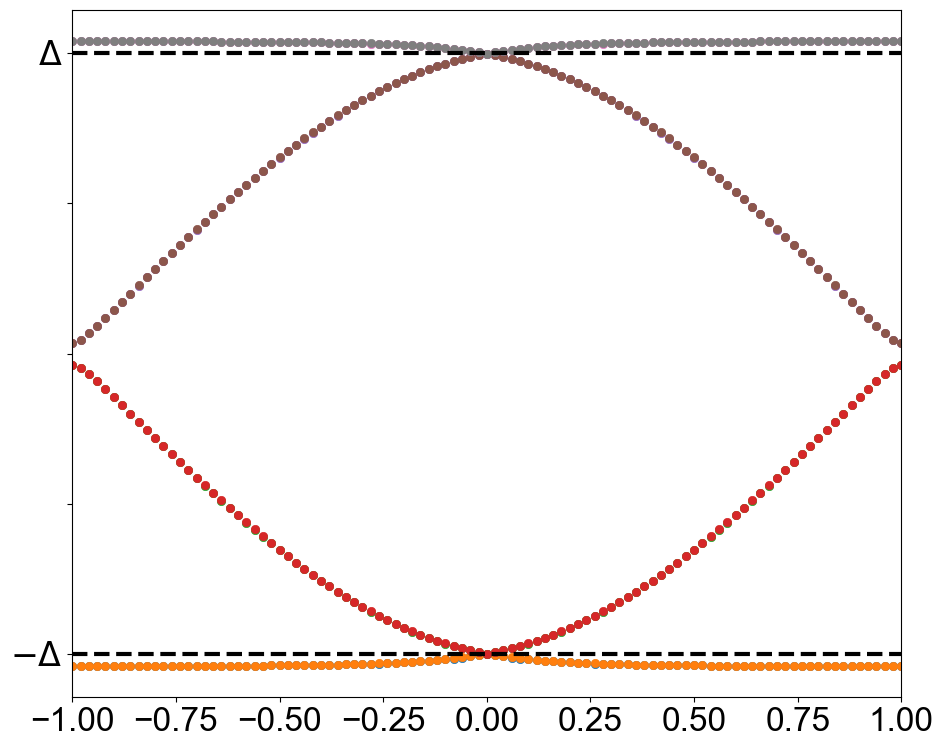

In [8]:
# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

ax = plt.axes()

#Ep2 = Ep[:,2:6]
Ep2_s = Ep_s[:,2:10]

for i in range(Ep2_s.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.scatter(PHI/np.pi, Ep2_s[:,i]/DELTA, lw=0.5)

# Increase the font size of the axes labels and title
#plt.xlabel(r'$\phi/\pi$', fontsize=24)
#plt.ylabel(r'Andreev bound state energy', fontsize=24)
#plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

#plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Specify ticks on the y-axis 
ax.set_yticks(np.linspace(-1,1,num=5))

# setting label for y tick 
ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 


# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.show()

first subband energy = 0.6631720133634798 
 second subband energy = 1.9895160400904393
mu_sc =  1.4631720133634798 mu_sm =  1.4631720133634798
0
10
20


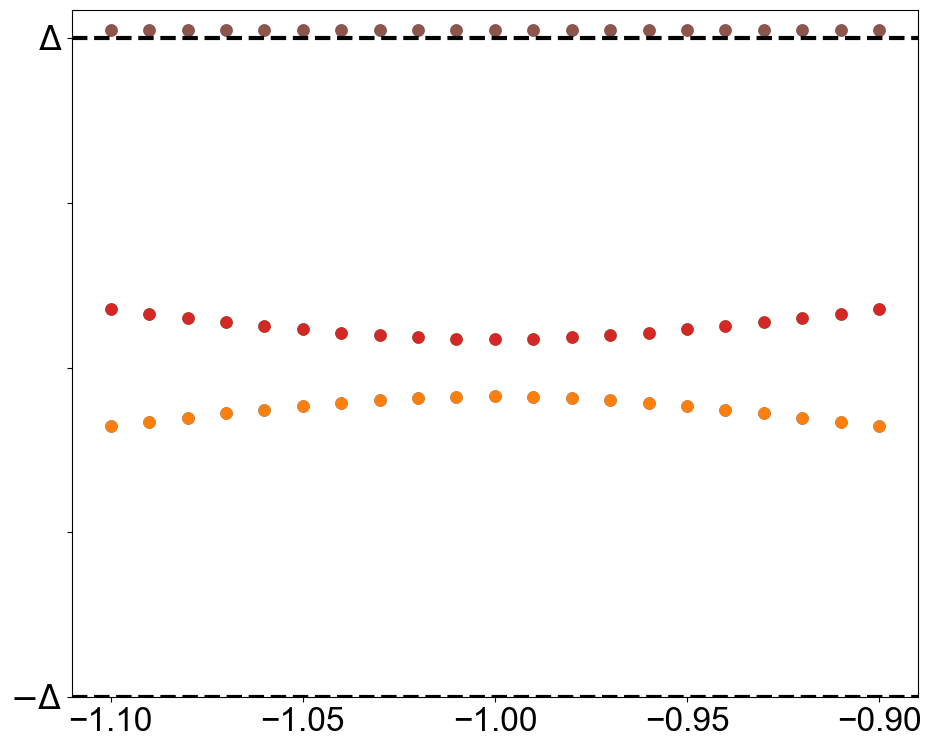

In [6]:
NSM = 1          # in nm
MY = 7             # no of subbands
AX = 2             # lattice spacing in nm
LY = 100           # Width in nm
ALPHAT = 20        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 1500
N = 2*NSC + NSM



print('first subband energy =' , OMEGA/2 , '\n', 'second subband energy =' , 3*OMEGA/2)

MU_SM = 0.8 + OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.8 + OMEGA/2        ## constant potential over reference level across all widths

print('mu_sc = ',MU_SC , 'mu_sm = ', MU_SM )

PHI = np.linspace(-1.1*np.pi,-0.9*np.pi,21)
K = 8

Ep_s = np.empty((PHI.shape[0],K))

D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

for i in range(PHI.shape[0]):

    H = D.H_sys(PHI[i], so='li' )
    
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    
    Ep_s[i,:] =np.sort(E)
    
    if i%10==0:
        print(i)


# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

ax = plt.axes()

#Ep2 = Ep[:,2:6]
Ep2_s = Ep_s[:,2:10]

for i in range(Ep2_s.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.scatter(PHI/np.pi, Ep2_s[:,i]/DELTA, lw=3)

# Increase the font size of the axes labels and title
#plt.xlabel(r'$\phi/\pi$', fontsize=24)
#plt.ylabel(r'Andreev bound state energy', fontsize=24)
#plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

#plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
#plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Specify ticks on the y-axis 
ax.set_yticks(np.linspace(-1,1,num=5))

# setting label for y tick 
ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 


# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.show()

first subband energy = 2.652688053453919 
 second subband energy = 7.958064160361757
mu_sc =  3.452688053453919 mu_sm =  3.452688053453919
0
10
20


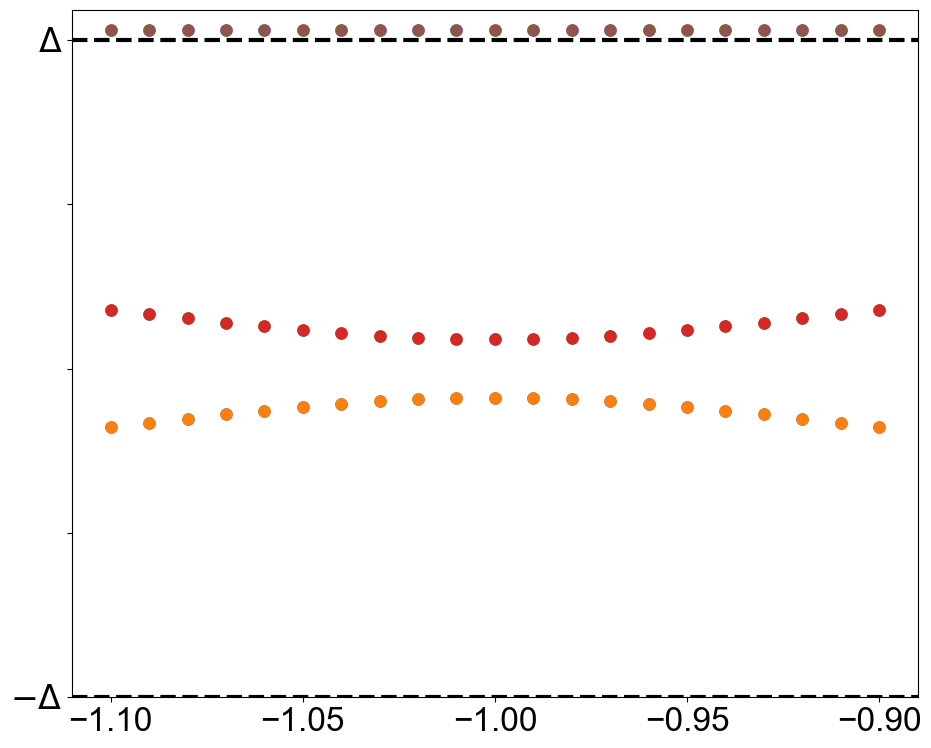

In [7]:
NSM = 1          # in nm
MY = 7             # no of subbands
AX = 2             # lattice spacing in nm
LY = 50           # Width in nm
ALPHAT = 20        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 1500
N = 2*NSC + NSM



print('first subband energy =' , OMEGA/2 , '\n', 'second subband energy =' , 3*OMEGA/2)

MU_SM = 0.8 + OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.8 + OMEGA/2        ## constant potential over reference level across all widths

print('mu_sc = ',MU_SC , 'mu_sm = ', MU_SM )

PHI = np.linspace(-1.1*np.pi,-0.9*np.pi,21)
K = 8

Ep_s = np.empty((PHI.shape[0],K))

D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

for i in range(PHI.shape[0]):

    H = D.H_sys(PHI[i], so='li' )
    
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    
    Ep_s[i,:] =np.sort(E)
    
    if i%10==0:
        print(i)


# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

ax = plt.axes()

#Ep2 = Ep[:,2:6]
Ep2_s = Ep_s[:,2:10]

for i in range(Ep2_s.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.scatter(PHI/np.pi, Ep2_s[:,i]/DELTA, lw=3)

# Increase the font size of the axes labels and title
#plt.xlabel(r'$\phi/\pi$', fontsize=24)
#plt.ylabel(r'Andreev bound state energy', fontsize=24)
#plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

#plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
#plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Specify ticks on the y-axis 
ax.set_yticks(np.linspace(-1,1,num=5))

# setting label for y tick 
ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 


# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.show()

first subband energy = 2.652688053453919 
 second subband energy = 7.958064160361757
mu_sc =  3.452688053453919 mu_sm =  3.452688053453919
0
10
20


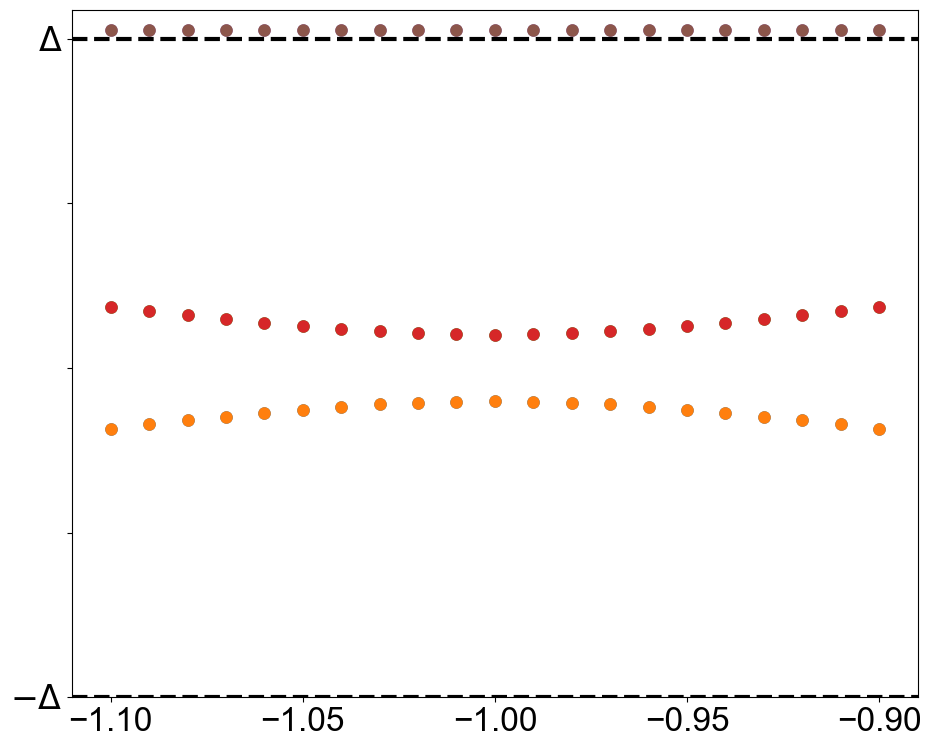

In [8]:
NSM = 1          # in nm
MY = 1             # no of subbands
AX = 2             # lattice spacing in nm
LY = 50           # Width in nm
ALPHAT = 0        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 1500
N = 2*NSC + NSM



print('first subband energy =' , OMEGA/2 , '\n', 'second subband energy =' , 3*OMEGA/2)

MU_SM = 0.8 + OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.8 + OMEGA/2        ## constant potential over reference level across all widths

print('mu_sc = ',MU_SC , 'mu_sm = ', MU_SM )

PHI = np.linspace(-1.1*np.pi,-0.9*np.pi,21)
K = 8

Ep_s = np.empty((PHI.shape[0],K))

D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

for i in range(PHI.shape[0]):

    H = D.H_sys(PHI[i], so='li' )
    
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    
    Ep_s[i,:] =np.sort(E)
    
    if i%10==0:
        print(i)


# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

ax = plt.axes()

#Ep2 = Ep[:,2:6]
Ep2_s = Ep_s[:,2:10]

for i in range(Ep2_s.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.scatter(PHI/np.pi, Ep2_s[:,i]/DELTA, lw=3)

# Increase the font size of the axes labels and title
#plt.xlabel(r'$\phi/\pi$', fontsize=24)
#plt.ylabel(r'Andreev bound state energy', fontsize=24)
#plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

#plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
#plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Specify ticks on the y-axis 
ax.set_yticks(np.linspace(-1,1,num=5))

# setting label for y tick 
ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 


# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.show()

first subband energy = 2.652688053453919 
 second subband energy = 7.958064160361757
mu_sc =  6.958064160361757 mu_sm =  6.958064160361757
0
10
20


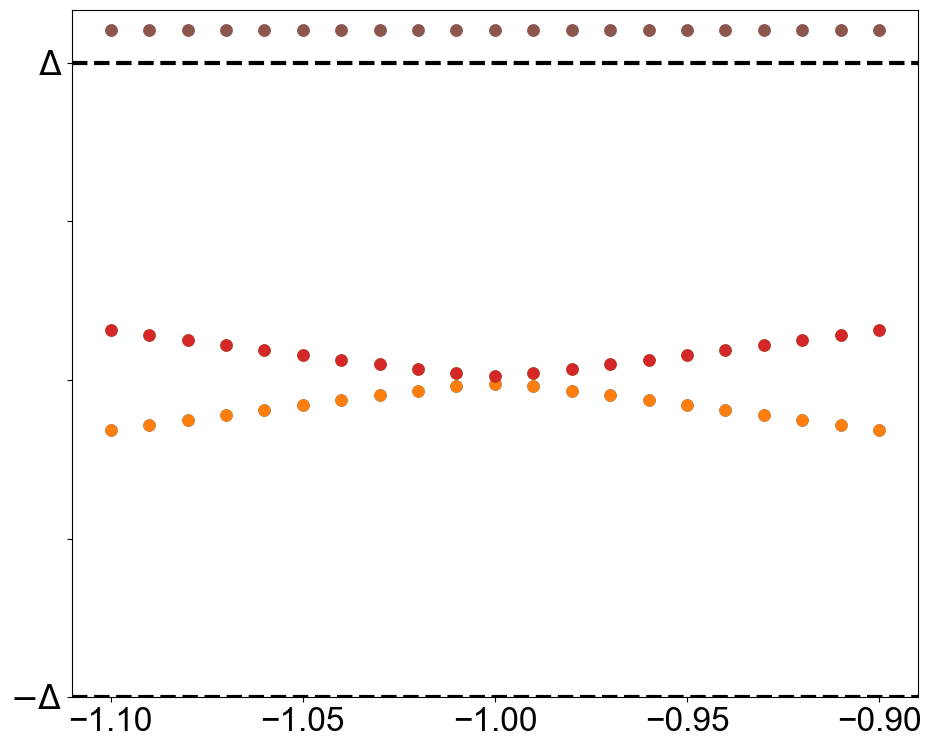

In [10]:
NSM = 1          # in nm
MY = 1             # no of subbands
AX = 2             # lattice spacing in nm
LY = 50           # Width in nm
ALPHAT = 0        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 1500
N = 2*NSC + NSM



print('first subband energy =' , OMEGA/2 , '\n', 'second subband energy =' , 3*OMEGA/2)

MU_SM = -1 + 3*OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = -1 + 3*OMEGA/2        ## constant potential over reference level across all widths

print('mu_sc = ',MU_SC , 'mu_sm = ', MU_SM )

PHI = np.linspace(-1.1*np.pi,-0.9*np.pi,21)
K = 8

Ep_s = np.empty((PHI.shape[0],K))

D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

for i in range(PHI.shape[0]):

    H = D.H_sys(PHI[i], so='li' )
    
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    
    Ep_s[i,:] =np.sort(E)
    
    if i%10==0:
        print(i)


# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

ax = plt.axes()

#Ep2 = Ep[:,2:6]
Ep2_s = Ep_s[:,2:10]

for i in range(Ep2_s.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.scatter(PHI/np.pi, Ep2_s[:,i]/DELTA, lw=3)

# Increase the font size of the axes labels and title
#plt.xlabel(r'$\phi/\pi$', fontsize=24)
#plt.ylabel(r'Andreev bound state energy', fontsize=24)
#plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

#plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
#plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Specify ticks on the y-axis 
ax.set_yticks(np.linspace(-1,1,num=5))

# setting label for y tick 
ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 


# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.show()

In [ ]:
NSM = 1          # in nm
MY = 7             # no of subbands
AX = 2             # lattice spacing in nm
LY = 50           # Width in nm
ALPHAT = 20        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 1500
N = 2*NSC + NSM



print('first subband energy =' , OMEGA/2 , '\n', 'second subband energy =' , 3*OMEGA/2)

MU_SM = 0.8 + OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.8 + OMEGA/2        ## constant potential over reference level across all widths

print('mu_sc = ',MU_SC , 'mu_sm = ', MU_SM )

PHI = np.linspace(-1.1*np.pi,-0.9*np.pi,21)
K = 8

Ep_s = np.empty((PHI.shape[0],K))

D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

for i in range(PHI.shape[0]):

    H = D.H_sys(PHI[i], so='li' )
    
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    
    Ep_s[i,:] =np.sort(E)
    
    if i%10==0:
        print(i)


# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

ax = plt.axes()

#Ep2 = Ep[:,2:6]
Ep2_s = Ep_s[:,2:10]

for i in range(Ep2_s.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.scatter(PHI/np.pi, Ep2_s[:,i]/DELTA, lw=3)

# Increase the font size of the axes labels and title
#plt.xlabel(r'$\phi/\pi$', fontsize=24)
#plt.ylabel(r'Andreev bound state energy', fontsize=24)
#plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

#plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
#plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Specify ticks on the y-axis 
ax.set_yticks(np.linspace(-1,1,num=5))

# setting label for y tick 
ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 


# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.show()

first subband energy = 0.6631720133634798 
 second subband energy = 1.9895160400904393
mu_sc =  1.4631720133634798 mu_sm =  1.4631720133634798
0
10
20


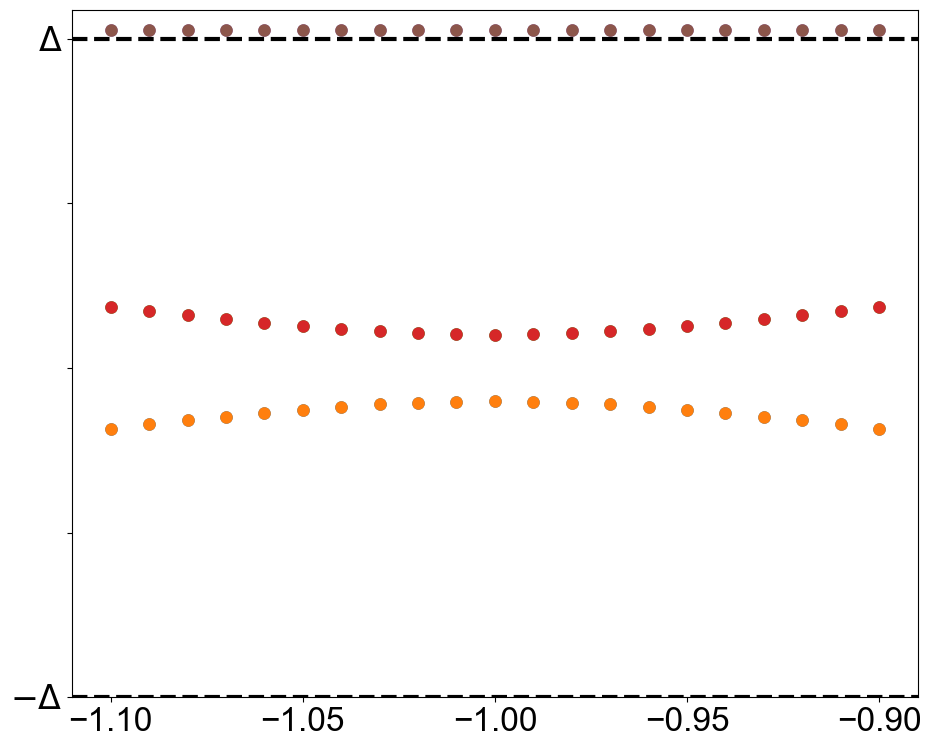

In [8]:
NSM = 1          # in nm
MY = 7             # no of subbands
AX = 2             # lattice spacing in nm
LY = 100           # Width in nm
ALPHAT = 0        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 1500
N = 2*NSC + NSM



print('first subband energy =' , OMEGA/2 , '\n', 'second subband energy =' , 3*OMEGA/2)

MU_SM = 0.8 + OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.8 + OMEGA/2        ## constant potential over reference level across all widths

print('mu_sc = ',MU_SC , 'mu_sm = ', MU_SM )

PHI = np.linspace(-1.1*np.pi,-0.9*np.pi,21)
K = 8

Ep_s = np.empty((PHI.shape[0],K))

D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

for i in range(PHI.shape[0]):

    H = D.H_sys(PHI[i], so='li' )
    
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    
    Ep_s[i,:] =np.sort(E)
    
    if i%10==0:
        print(i)


# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

ax = plt.axes()

#Ep2 = Ep[:,2:6]
Ep2_s = Ep_s[:,2:10]

for i in range(Ep2_s.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.scatter(PHI/np.pi, Ep2_s[:,i]/DELTA, lw=3)

# Increase the font size of the axes labels and title
#plt.xlabel(r'$\phi/\pi$', fontsize=24)
#plt.ylabel(r'Andreev bound state energy', fontsize=24)
#plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

#plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
#plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Specify ticks on the y-axis 
ax.set_yticks(np.linspace(-1,1,num=5))

# setting label for y tick 
ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 


# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.show()

first subband energy = 0.6631720133634798 
 second subband energy = 1.9895160400904393
mu_sc =  1.4631720133634798 mu_sm =  1.4631720133634798
0
10
20


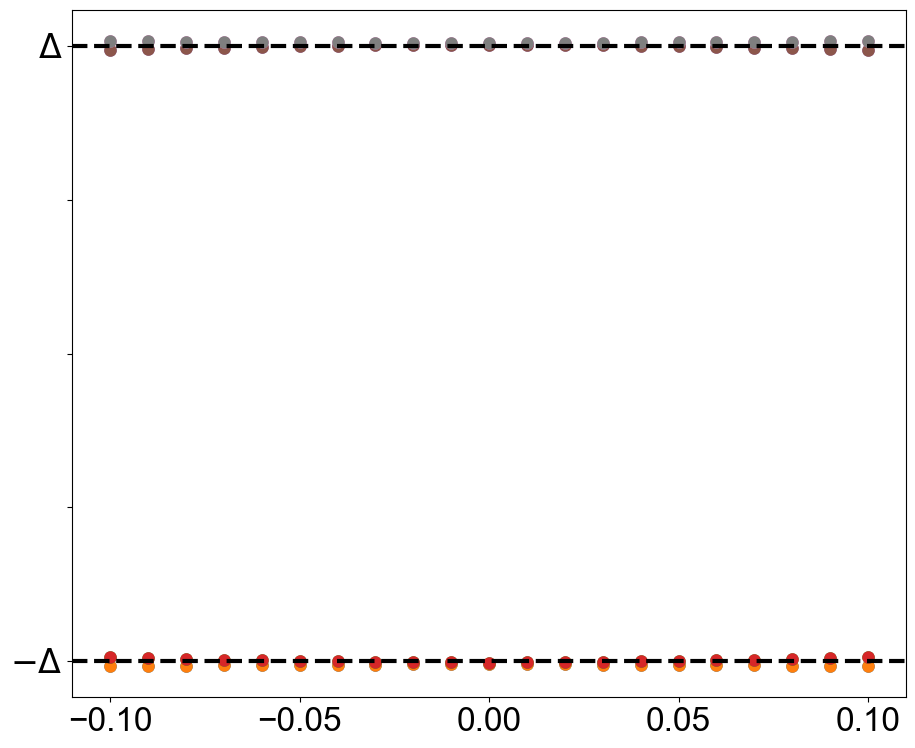

In [3]:
NSM = 1          # in nm
MY = 7             # no of subbands
AX = 2             # lattice spacing in nm
LY = 100           # Width in nm
ALPHAT = 20        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 1500
N = 2*NSC + NSM



print('first subband energy =' , OMEGA/2 , '\n', 'second subband energy =' , 3*OMEGA/2)

MU_SM = 0.8 + OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.8 + OMEGA/2        ## constant potential over reference level across all widths

print('mu_sc = ',MU_SC , 'mu_sm = ', MU_SM )

PHI = np.linspace(-0.1*np.pi,0.1*np.pi,21)
K = 8

Ep_s = np.empty((PHI.shape[0],K))

D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

for i in range(PHI.shape[0]):

    H = D.H_sys(PHI[i], so='li' )
    
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    
    Ep_s[i,:] =np.sort(E)
    
    if i%10==0:
        print(i)


# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

ax = plt.axes()

#Ep2 = Ep[:,2:6]
#Ep2_s = Ep_s[:,2:10]
Ep2_s = Ep_s[:, :]

for i in range(Ep2_s.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.scatter(PHI/np.pi, Ep2_s[:,i]/DELTA, lw=3)

# Increase the font size of the axes labels and title
#plt.xlabel(r'$\phi/\pi$', fontsize=24)
#plt.ylabel(r'Andreev bound state energy', fontsize=24)
#plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

#plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
#plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Specify ticks on the y-axis 
ax.set_yticks(np.linspace(-1,1,num=5))

# setting label for y tick 
ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 


# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.show()

first subband energy = 0.6631720133634798 
 second subband energy = 1.9895160400904393
mu_sc =  1.4631720133634798 mu_sm =  1.4631720133634798
0
10
20


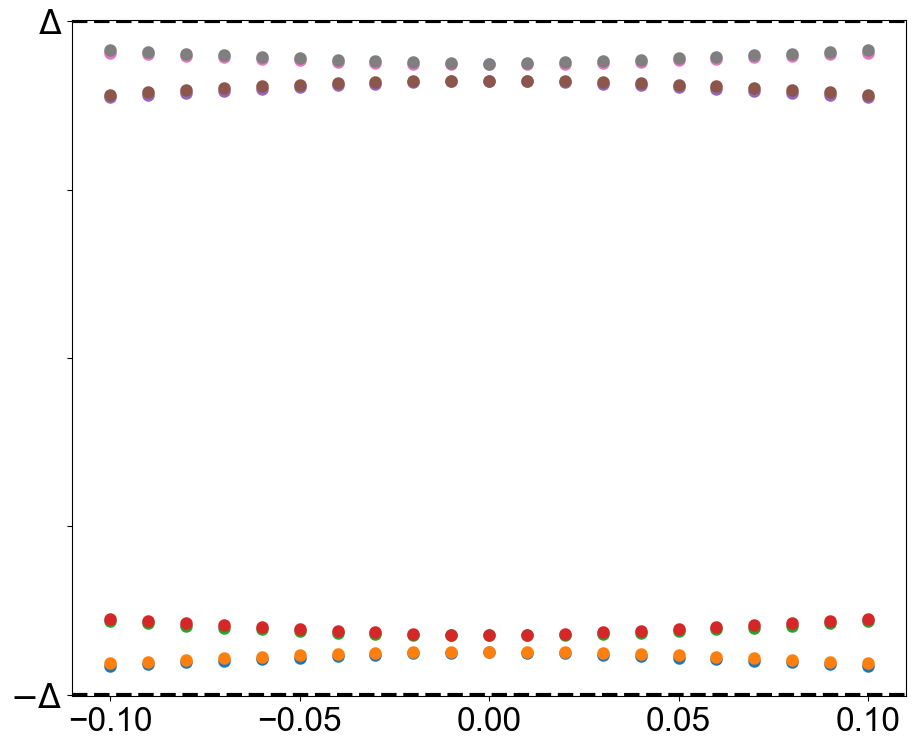

In [4]:
NSM = 60          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
LY = 100           # Width in nm
ALPHAT = 20        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 1500
N = 2*NSC + NSM



print('first subband energy =' , OMEGA/2 , '\n', 'second subband energy =' , 3*OMEGA/2)

MU_SM = 0.8 + OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.8 + OMEGA/2        ## constant potential over reference level across all widths

print('mu_sc = ',MU_SC , 'mu_sm = ', MU_SM )

PHI = np.linspace(-0.1*np.pi,0.1*np.pi,21)
K = 8

Ep_s = np.empty((PHI.shape[0],K))

D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

for i in range(PHI.shape[0]):

    H = D.H_sys(PHI[i], so='li' )
    
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    
    Ep_s[i,:] =np.sort(E)
    
    if i%10==0:
        print(i)


# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

ax = plt.axes()

#Ep2 = Ep[:,2:6]
#Ep2_s = Ep_s[:,2:10]
Ep2_s = Ep_s[:, :]

for i in range(Ep2_s.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.scatter(PHI/np.pi, Ep2_s[:,i]/DELTA, lw=3)

# Increase the font size of the axes labels and title
#plt.xlabel(r'$\phi/\pi$', fontsize=24)
#plt.ylabel(r'Andreev bound state energy', fontsize=24)
#plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

#plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
#plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Specify ticks on the y-axis 
ax.set_yticks(np.linspace(-1,1,num=5))

# setting label for y tick 
ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 


# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.show()

first subband energy = 0.6631720133634798 
 second subband energy = 1.9895160400904393
mu_sc =  1.4631720133634798 mu_sm =  1.4631720133634798
0
10
20


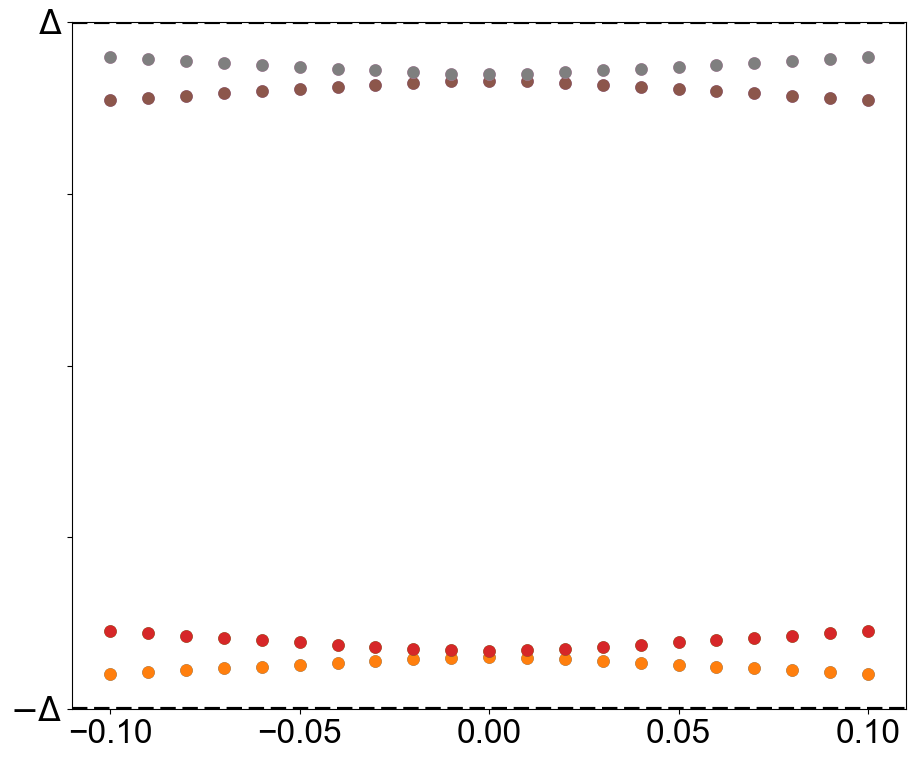

In [5]:
NSM = 60          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
LY = 100           # Width in nm
ALPHAT = 0        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 1500
N = 2*NSC + NSM



print('first subband energy =' , OMEGA/2 , '\n', 'second subband energy =' , 3*OMEGA/2)

MU_SM = 0.8 + OMEGA/2        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.8 + OMEGA/2        ## constant potential over reference level across all widths

print('mu_sc = ',MU_SC , 'mu_sm = ', MU_SM )

PHI = np.linspace(-0.1*np.pi,0.1*np.pi,21)
K = 8

Ep_s = np.empty((PHI.shape[0],K))

D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

for i in range(PHI.shape[0]):

    H = D.H_sys(PHI[i], so='li' )
    
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    
    Ep_s[i,:] =np.sort(E)
    
    if i%10==0:
        print(i)


# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'

plt.rc('font', size=24)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

ax = plt.axes()

#Ep2 = Ep[:,2:6]
#Ep2_s = Ep_s[:,2:10]
Ep2_s = Ep_s[:, :]

for i in range(Ep2_s.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.scatter(PHI/np.pi, Ep2_s[:,i]/DELTA, lw=3)

# Increase the font size of the axes labels and title
#plt.xlabel(r'$\phi/\pi$', fontsize=24)
#plt.ylabel(r'Andreev bound state energy', fontsize=24)
#plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

#plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
#plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Specify ticks on the y-axis 
ax.set_yticks(np.linspace(-1,1,num=5))

# setting label for y tick 
ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 


# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.show()

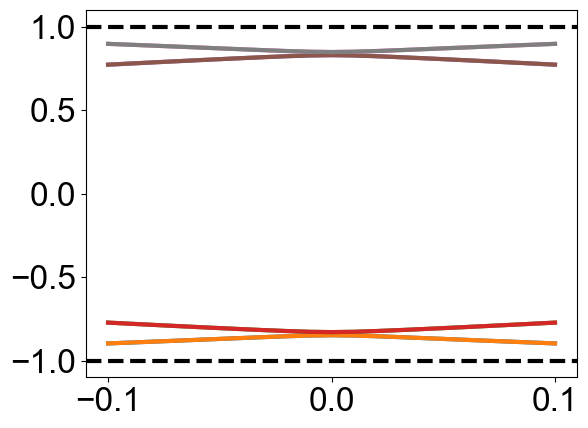

In [6]:
for i in range(Ep2_s.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.plot(PHI/np.pi, Ep2_s[:,i]/DELTA, lw=3)

# Increase the font size of the axes labels and title
#plt.xlabel(r'$\phi/\pi$', fontsize=24)
#plt.ylabel(r'Andreev bound state energy', fontsize=24)
#plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

#plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
#plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Specify ticks on the y-axis 
ax.set_yticks(np.linspace(-1,1,num=5))

# setting label for y tick 
ax.set_yticklabels([r'$-\Delta$','','','', r'$\Delta$'], fontsize=24) 


# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.show()

In [45]:
NSM = 100          # in nm
MY = 7             # no of subbands
AX = 1             # lattice spacing in nm
LY = 100           # Width in nm
ALPHAT = 78        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 2000
N = 2*NSC + NSM



print('first subband energy =' , OMEGA/2 , '\n', 'second subband energy =' , 3*OMEGA/2)

MU_SC =  OMEGA   #in between two subbands
MU_SM =  OMEGA   #in between two subbands

print('mu_sc = ',MU_SC)

PHI = np.linspace(-1*np.pi,1*np.pi,101)
K = 12

Ep_s = np.empty((PHI.shape[0],K))

D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

for i in range(PHI.shape[0]):

    H = D.H_sys(PHI[i], so='li' )
    
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    
    Ep_s[i,:] =np.sort(E)
    
    if i%10==0:
        print(i)

first subband energy = 0.6631720133634798 
 second subband energy = 1.9895160400904393
mu_sc =  1.3263440267269595
0
10
20


KeyboardInterrupt: 